# Naive baselines

**Goal:** measure how well simple, transparent estimates do, so that every later model is judged against them. A model that barely beats "the median price of the same town and flat type", which HDB already publishes, brings a buyer nothing.

**Output:** the baselines' backtest scores, the training-window setting chosen for them, and the decisions they lead to (recorded in [section 4](#toc-4)). The baselines and the backtest harness live in the `hdb_resale` package (`baselines.py`, `backtest.py`); this notebook only runs and reads them.

**Data:** the cleaned table `data/interim/resale.parquet`. To build it: `uv run dvc pull`, then `uv run hdb-resale clean`.

**Rule for this notebook:** settings are chosen on the **validation period** (the 12 months before the test period, Oct 2024 to Sep 2025) and the result is reported **once** on the **test period** (Oct 2025 to Sep 2026, project ADR-0001). Choosing a setting by its test score would flatter it: see [section 2](#toc-2).

## Table of Contents

- [1. The baselines](#toc-1)
- [2. Choosing the training window on the validation period](#toc-2)
- [3. The baselines on the test period](#toc-3)
- [4. Summary: decisions](#toc-4)

<a id="toc-1"></a>

## 1. The baselines

Each baseline adds one piece of information to the previous one:

| | Baseline | Estimate for a flat |
|---|---|---|
| 0 | **Overall median** | the median resale price of all training sales: the floor |
| 1 | **Town + flat type median** | the median resale price of recent sales of the same town and flat type |
| 2 | **Town + flat type, per m²** | that group's median price per m², times the flat's floor area |

**Recent sales only.** Prices rose about 50% between 2020 and 2025 ([EDA](01-eda.ipynb), section 2), so a median over all history since 2017 would be badly out of date. Baselines 1 and 2 only use the latest *N* months of training sales; *N* is chosen in section 2.

**Empty groups fall back** to a broader group: a 1-room flat in a town with no recent 1-room sale gets the median of 1-room flats in all towns, and a flat type with no recent sale at all gets the median of all recent sales. Every flat always gets an estimate.

**Hypotheses:** baseline 1 is far more accurate than baseline 0, since town and flat type are the two strongest categorical drivers of price (EDA, section 3); baseline 2 improves on baseline 1, since floor area varies widely within a flat type.

**Metrics:** the backtest reports four candidate metrics per window (`score()`): MAE in S\$, MAPE, MdAPE (the median error in %) and log-space MAE. The primary metric is chosen after the residual analysis; until then, settings are compared on **MdAPE**, the typical error a buyer would face, after checking that the other metrics rank them the same way.

In [1]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import pandas as pd

from hdb_resale.backtest import backtest, score
from hdb_resale.baselines import OverallMedian, TownFlatTypeMedian

# Chart style: recessive grid and axes, thin lines; one fixed colour order for categories
plt.rcParams.update(
    {
        "figure.dpi": 110,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "grid.color": "#e6e5e0",
        "axes.edgecolor": "#52514e",
        "axes.labelcolor": "#0b0b0b",
        "text.color": "#0b0b0b",
        "lines.linewidth": 2,
    }
)
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
percent = mticker.PercentFormatter(xmax=1, decimals=0)

# The notebook runs from notebooks/, the data lives at the project root
cleaned = pd.read_parquet("../data/interim/resale.parquet")

# First month of the test period: validation runs stop just before it
TEST_START = "2025-10"
print(
    f"{len(cleaned):,} cleaned sales, {cleaned['month'].min()} to {cleaned['month'].max()}"
)

242,537 cleaned sales, 2017-01 to 2026-10


<a id="toc-2"></a>

## 2. Choosing the training window on the validation period

How many recent months should the group medians use? Fewer months follow the market more closely; more months give each group more sales and steadier medians. Each option (3, 6, 12, 24 months) gets a **complete backtest** on the validation period.

**Why the validation period, not the test period.** Picking the option with the best *test* score would make that score dishonest: the winner wins partly because it happened to suit those particular months (the *winner's curse*), so its score overstates how it will do on future months. Choosing on validation months and reporting on test months keeps the test score an honest estimate: the test months play no part in the choice.

**Signal or luck?** A lower average error isn't enough. The options are also compared **month by month**: an option that wins in most of the 12 validation months is genuinely better; one that wins about half the time is indistinguishable, and the simpler or steadier option is kept.

In [2]:
# A complete validation backtest per option: both group-median baselines x 4 windows
WINDOWS = [3, 6, 12, 24]
validation = {
    (per_sqm, months): score(
        backtest(
            cleaned,
            TownFlatTypeMedian(recent_months=months, per_sqm=per_sqm),
            end=TEST_START,
        )
    )
    for per_sqm in [False, True]
    for months in WINDOWS
}

# Average over the 12 validation windows, one row per option
summary = pd.DataFrame(
    {
        ("per m²" if per_sqm else "price", months): scores[
            ["mdape", "mape", "log_mae", "mae"]
        ].mean()
        for (per_sqm, months), scores in validation.items()
    }
).T
summary.index.names = ["median of", "months"]
summary.style.format(
    {"mdape": "{:.2%}", "mape": "{:.2%}", "log_mae": "{:.4f}", "mae": "S${:,.0f}"}
)

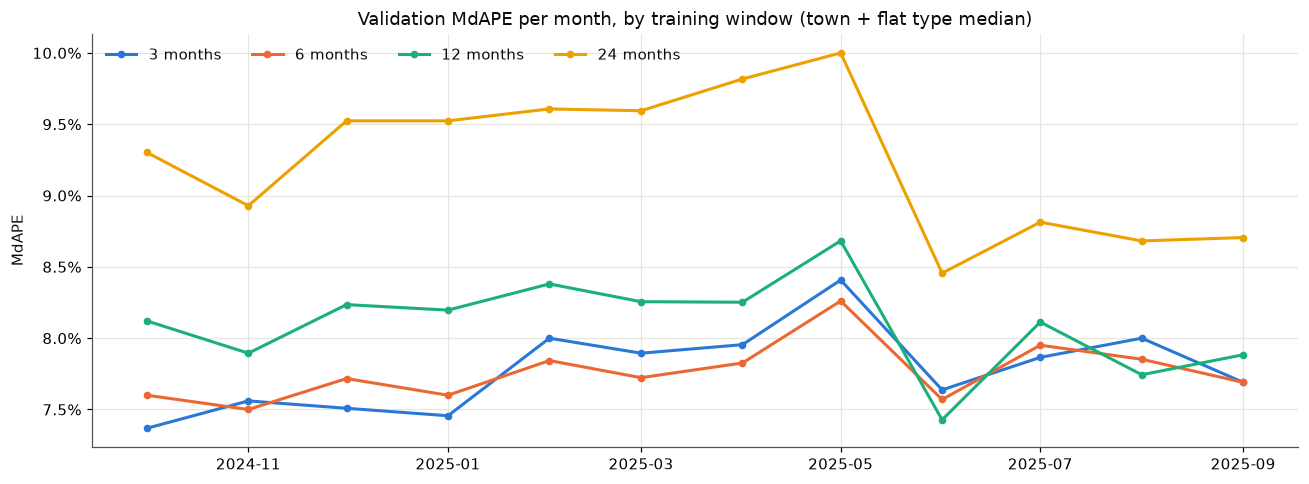

In [3]:
# MdAPE per validation month, for each window (baseline 1: median price)
fig, ax = plt.subplots(figsize=(12, 4.5))
for color, months in zip(SERIES, WINDOWS, strict=True):
    mdape = validation[(False, months)]["mdape"]
    ax.plot(
        mdape.index.to_timestamp(),
        mdape,
        color=color,
        marker="o",
        markersize=4,
        label=f"{months} months",
    )
ax.yaxis.set_major_formatter(mticker.PercentFormatter(xmax=1, decimals=1))  # gaps < 1%
ax.legend(frameon=False, ncols=4, loc="upper left")
ax.set(
    title="Validation MdAPE per month, by training window (town + flat type median)",
    ylabel="MdAPE",
)
plt.tight_layout()

In [4]:
# Month by month: in how many of the 12 validation months does each window beat the others?
for per_sqm in [False, True]:
    mdape = pd.DataFrame(
        {months: validation[(per_sqm, months)]["mdape"] for months in WINDOWS}
    )
    head_to_head = pd.DataFrame(
        {other: (mdape[months] < mdape[other]).sum() for other in WINDOWS}
        for months in WINDOWS
    )
    head_to_head.index = WINDOWS
    label = "per m²" if per_sqm else "price"
    print(f"Median of {label}: months (of 12) the row window beats the column window")
    print(head_to_head.to_string(), "\n")

Median of price: months (of 12) the row window beats the column window
    3   6   12  24
3    0   4  10  12
6    7   0  10  12
12   2   2   0  12
24   0   0   0   0 

Median of per m²: months (of 12) the row window beats the column window
    3   6   12  24
3    0   5   6  12
6    7   0   9  12
12   6   3   0  12
24   0   0   0   0 



In [5]:
# Reference: the overall median on the same validation months
overall_validation = score(backtest(cleaned, OverallMedian(), end=TEST_START))
print(f"Overall median, validation MdAPE: {overall_validation['mdape'].mean():.1%}")

Overall median, validation MdAPE: 26.0%


### Findings (section 2)

- **The window matters, up to a point.** 3 and 6 months score the same on validation (MdAPE 7.8%), 12 months is slightly worse (8.1%), 24 months clearly worse (9.3%): with prices moving, older sales pull the medians away from today's market.
- **6 months beats 12 in 10 of the 12 validation months**, a consistent difference rather than luck. **6 vs 3 is a draw** (7 months to 4): indistinguishable, so we keep **6 months**, which gives each group twice as many sales and steadier medians.
- **The other metrics agree** (MAPE, log-space MAE, MAE in S\$ rank the windows the same way, with 3 and 6 within noise of each other), so the choice doesn't depend on the metric.
- Both group-median baselines are **about 3x more accurate than the overall median** on validation (7.8% vs 26.0%).

<a id="toc-3"></a>

## 3. The baselines on the test period

Each baseline runs **once** on the test period, with the window chosen in section 2.

In [6]:
# The chosen window (section 2), then one test backtest per baseline
CHOSEN_MONTHS = 6
baselines = {
    "0. Overall median": OverallMedian(),
    "1. Town + flat type": TownFlatTypeMedian(recent_months=CHOSEN_MONTHS),
    "2. Town + flat type, per m²": TownFlatTypeMedian(
        recent_months=CHOSEN_MONTHS, per_sqm=True
    ),
}
test = {name: score(backtest(cleaned, model)) for name, model in baselines.items()}

# Average over the 12 test windows, and the spread from month to month
results = pd.DataFrame(
    {
        name: {
            "MdAPE": scores["mdape"].mean(),
            "MdAPE, worst month": scores["mdape"].max(),
            "MAPE": scores["mape"].mean(),
            "log-space MAE": scores["log_mae"].mean(),
            "MAE (S$)": scores["mae"].mean(),
        }
        for name, scores in test.items()
    }
).T
results.style.format(
    {
        "MdAPE": "{:.1%}",
        "MdAPE, worst month": "{:.1%}",
        "MAPE": "{:.1%}",
        "log-space MAE": "{:.3f}",
        "MAE (S$)": "S${:,.0f}",
    }
)

,MdAPE,"MdAPE, worst month",MAPE,log-space MAE,MAE (S$)
0. Overall median,25.5%,27.2%,27.1%,0.324,"S$202,483"
1. Town + flat type,8.6%,9.4%,12.0%,0.122,"S$81,859"
"2. Town + flat type, per m²",8.9%,9.6%,12.3%,0.126,"S$85,472"


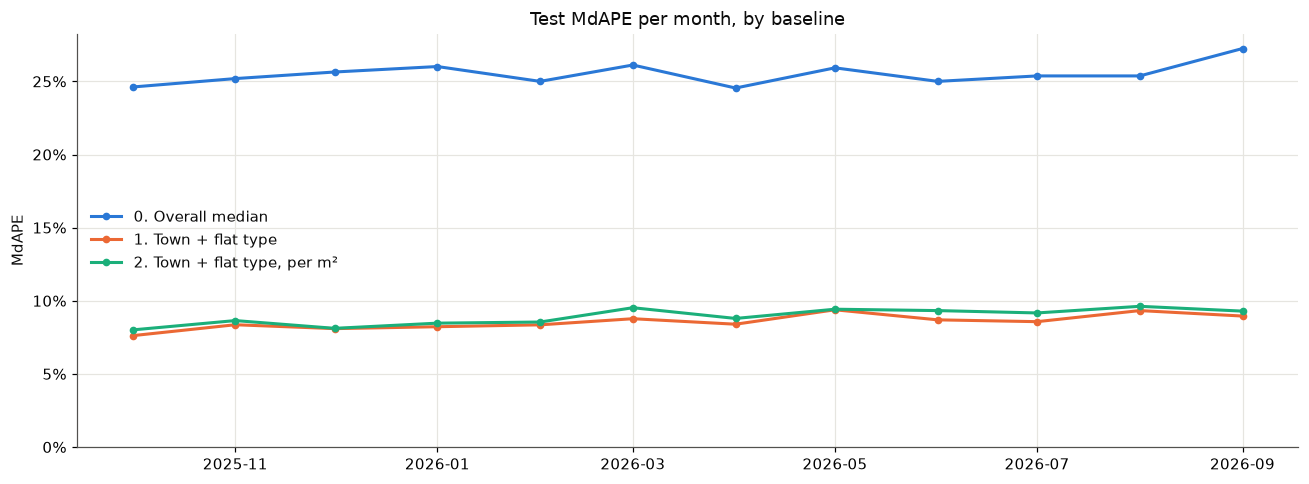

In [7]:
# MdAPE per test month, for each baseline
fig, ax = plt.subplots(figsize=(12, 4.5))
for color, (name, scores) in zip(SERIES, test.items(), strict=False):
    ax.plot(
        scores.index.to_timestamp(),
        scores["mdape"],
        color=color,
        marker="o",
        markersize=4,
        label=name,
    )
ax.yaxis.set_major_formatter(percent)
ax.set_ylim(bottom=0)
ax.legend(frameon=False, loc="center left")
ax.set(title="Test MdAPE per month, by baseline", ylabel="MdAPE")
plt.tight_layout()

In [8]:
# How often does each fallback level serve a test flat? (baseline 1, chosen window)
fallback = {}
for test_month in sorted(test["1. Town + flat type"].index):
    train = cleaned[cleaned["month"] < test_month]
    recent = train[train["month"] > test_month - 1 - CHOSEN_MONTHS]
    groups = set(zip(recent["town"], recent["flat_type"], strict=True))
    month_sales = cleaned[cleaned["month"] == test_month]
    fallback[test_month] = (
        ~pd.Series(
            list(zip(month_sales["town"], month_sales["flat_type"], strict=True))
        ).isin(groups)
    ).mean()
print(
    f"Test flats whose town + flat type group was empty: {pd.Series(fallback).mean():.2%} on average"
)

Test flats whose town + flat type group was empty: 0.01% on average


In [9]:
# Why per m² doesn't help: within the same town, flat type and month, how does price scale with size?
same_group = ["town", "flat_type", "month"]
pre_test = cleaned[cleaned["month"] < pd.Period(TEST_START, freq="M")].copy()
pre_test["price_per_sqm"] = pre_test["resale_price"] / pre_test["floor_area_sqm"]
relative = pd.DataFrame(
    {
        name: pre_test[name] / pre_test.groupby(same_group)[name].transform("median")
        for name in ["floor_area_sqm", "resale_price", "price_per_sqm"]
    }
)
size_band = pd.cut(relative["floor_area_sqm"], [0, 0.9, 0.97, 1.03, 1.1, 5])
relative.groupby(size_band, observed=True)[
    ["resale_price", "price_per_sqm"]
].median().round(3)

,resale_price,price_per_sqm
floor_area_sqm,,
"(0.0, 0.9]",0.918,1.047
"(0.9, 0.97]",0.975,1.030
"(0.97, 1.03]",1.000,1.004
"(1.03, 1.1]",1.000,0.960
"(1.1, 5.0]",1.024,0.923


### Findings (section 3)

- **Town + flat type median (6 months): MdAPE 8.6% on the test period**, against 25.5% for the overall median, about 3x better. Half of the test sales are within 8.6% of this estimate; the average error is S\$82k (MAE), and the worst month stays under 9.4%: stable from month to month.
- **The per m² variant doesn't help** (8.9%), contrary to the hypothesis. Within the same town, flat type and month, a flat 10% larger than its group's median sells for only about 2% more, not 10%: its price per m² is lower. Scaling the price per m² by floor area therefore overestimates large flats. Size within a flat type is entangled with other drivers (older flats tend to be larger, EDA section 3), which only a model seeing all drivers together can separate.
- **The test score is a little worse than validation** (8.6% vs 7.8%). That's expected: the window was chosen as the validation winner, so its validation score is slightly flattering (the winner's curse), and the market moves from year to year. The test score is the honest one.
- **Fallbacks are rare**: 0.01% of test flats had no recent sale in their town and flat type group.

<a id="toc-4"></a>

## 4. Summary: decisions

| Finding | Decision |
|---|---|
| Town + flat type median with a 6-month window: test MdAPE 8.6% (S\$82k MAE) | **The reference baseline**: every model is reported next to it, and must beat it clearly to be worth its complexity. It's also the comparison for the CI quality gate (roadmap step 5) |
| 6 months beats 12 consistently on validation and ties with 3 | Window fixed at **6 months**, chosen on validation only |
| Per m² scaling is no better: price grows far less than proportionally with size within a group | Per m² variant dropped; size is left to models that see all drivers together |
| The overall median is 3x worse | Kept only as the floor, as a sanity check |
| Test slightly worse than validation | Expected (winner's curse); models are always reported on the test period, never on the period used to choose their settings |